# Food Analysis Sales Visualization

This notebook connects to the Oracle `FOOD_ANALYSIS` database, loads reporting data with pandas, and creates visualizations for:
- Top 10 customers by sales
- Top 10 cities by total sales

In [13]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv()

connection_url = URL.create(
    "oracle+oracledb",
    username=os.environ["ORACLE_USER"],
    password=os.environ["ORACLE_PASSWORD"],
    host="localhost",
    port=1522,
    query={"service_name": "FREEPDB1"},
)
engine = create_engine(connection_url)
print("Connected to Oracle.")

Connected to Oracle.


## Top 10 customers by sales

Load data from the `VW_TOP_10_CUSTOMERS_BY_SALES` view.

In [14]:
top_customers = pd.read_sql(
    """
    SELECT customer_id, customer_name, city, total_orders, total_sales
    FROM vw_top_10_customers_by_sales
    ORDER BY total_sales DESC
    """,
    engine,
)
top_customers

,customer_id,customer_name,city,total_orders,total_sales
0,C0079,Aarav Das,Bengaluru,10,4280
1,C0111,Vikram Sharma,Bengaluru,7,4280
2,C0107,Kiran Reddy,Bengaluru,9,4250
3,C0042,Sanjay Sharma,Bengaluru,10,4055
4,C0062,Abhishek Reddy,Bengaluru,8,3950
5,C0039,Rohan Nair,Bengaluru,10,3855
6,C0099,Meera Kumar,Bengaluru,9,3845
7,C0065,Priya Gowda,Bengaluru,9,3770
8,C0116,Ishaan Menon,Bengaluru,9,3765
9,C0032,Suresh Bhat,Bengaluru,7,3725


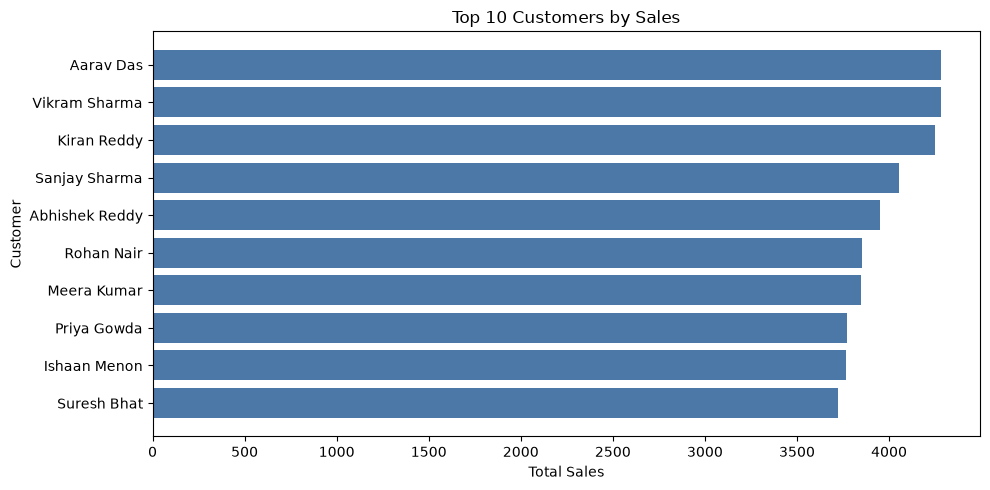

In [15]:
plt.figure(figsize=(10, 5))
plt.barh(top_customers["customer_name"], top_customers["total_sales"], color="#4C78A8")
plt.gca().invert_yaxis()
plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

## Top 10 cities by total sales

Load data from the `VW_TOP_10_CITIES_BY_SALES` view.

In [16]:
top_cities = pd.read_sql(
    """
    SELECT city, total_customers, total_orders, total_sales
    FROM vw_top_10_cities_by_sales
    ORDER BY total_sales DESC
    """,
    engine,
)
top_cities

,city,total_customers,total_orders,total_sales
0,Bengaluru,119,600,245815


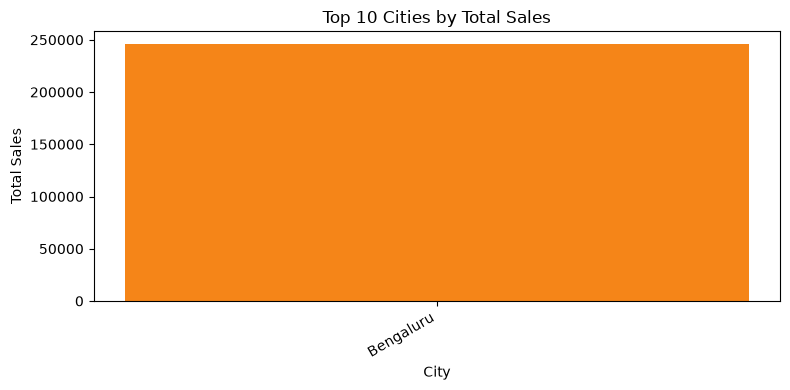

In [17]:
plt.figure(figsize=(8, 4))
plt.bar(top_cities["city"], top_cities["total_sales"], color="#F58518")
plt.title("Top 10 Cities by Total Sales")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()